# Неделя 09. Линейная регрессия: от формулы до проверяемого прогноза

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** вывести градиент MSE, реализовать два решения least squares, сравнить их со scikit-learn и проверить, что регуляризация выбрана без test.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_09_linear_regression'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'diabetes_raw.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (331, 10), 'sealed_test': (111, 10)}


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
sample_id,,,,,,,,,,
16,47,1,30.3,109.0,207,100.2,70.0,3.00,5.2149,98
408,66,1,21.7,126.0,212,127.8,45.0,4.71,5.2781,101
432,51,1,31.5,93.0,231,144.0,49.0,4.70,5.2523,117


## 1. Описательная аналитика обучающей выборки

До модели выясним, что означает цель и в каких шкалах измерены признаки.
Среднее и медиана описывают центр, стандартное отклонение — разброс;
корреляция измеряет линейную связь, но не доказывает причинность.
**Вопрос:** почему нельзя сравнивать величины raw-коэффициентов BMI и возраста
без учёта единиц измерения?


,count,mean,std,min,25%,50%,75%,max
age,331.0,48.80,12.79,19.00,39.0,50.00,59.00,79.00
sex,331.0,1.47,0.50,1.00,1.0,1.00,2.00,2.00
bmi,331.0,26.59,4.38,18.10,23.5,25.90,29.50,41.30
bp,331.0,95.02,13.91,62.00,84.0,93.00,105.00,133.00
s1,331.0,189.55,34.98,110.00,163.5,187.00,209.00,301.00
s2,331.0,115.47,30.85,41.60,94.8,113.00,133.90,242.40
s3,331.0,49.63,12.79,22.00,41.0,48.00,57.00,99.00
s4,331.0,4.09,1.31,2.00,3.0,4.00,5.00,9.09
s5,331.0,4.66,0.53,3.26,4.3,4.63,5.02,6.11
s6,331.0,92.05,11.46,58.00,84.0,92.00,99.00,124.00


,target
count,331.000000
mean,154.344411
std,77.864893
min,25.000000
25%,86.500000
50%,142.000000
75%,214.000000
max,346.000000


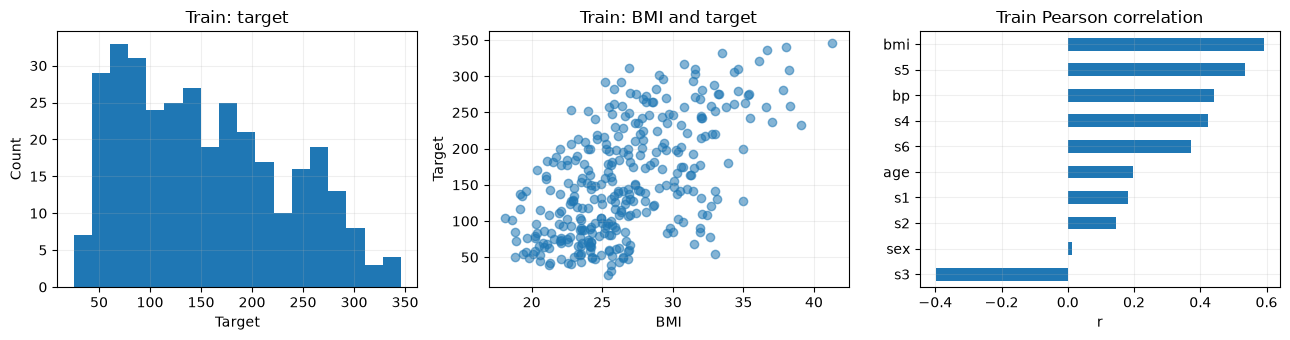

In [3]:
display(X_train.describe().T.round(2))
display(y_train.describe().to_frame("target"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
y_train.hist(bins=18, ax=axes[0]); axes[0].set(title="Train: target", xlabel="Target", ylabel="Count")
axes[1].scatter(X_train["bmi"], y_train, alpha=0.55)
axes[1].set(title="Train: BMI and target", xlabel="BMI", ylabel="Target")
corr = X_train.join(y_train).corr()["target"].drop("target").sort_values()
corr.plot.barh(ax=axes[2]); axes[2].set(title="Train Pearson correlation", xlabel="r")
plt.tight_layout(); plt.show()


## 2. Модель, функция потерь и градиент

Допишем к матрице столбец единиц: $A=[1,X]$. Тогда $\hat y=A\theta$,
где $\theta_0$ — свободный член.

$$J(\theta)=\frac1n\|A\theta-y\|_2^2,\qquad
\nabla J(\theta)=\frac{2}{n}A^\top(A\theta-y).$$

Обновление: $\theta\leftarrow\theta-\eta\nabla J$.
Нормальные уравнения полезны для вывода, но явно обращать $A^TA$ численно
невыгодно: `lstsq` использует более устойчивое разложение.
Стандартизация обучается **только на train**, цель нормируем для наглядной шкалы loss.


In [4]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
A = np.column_stack([np.ones(len(X_train)), scaler.transform(X_train)])
target_mean, target_std = y_train.mean(), y_train.std(ddof=0)
z = (y_train.to_numpy() - target_mean) / target_std
theta_ls, _, rank, singular_values = np.linalg.lstsq(A, z, rcond=None)
assert rank == A.shape[1]
print("Матрица A:", A.shape, "; condition number:", round(np.linalg.cond(A), 2))


Матрица A: (331, 11) ; condition number: 20.44


## 3. Градиентный спуск с контролем сходимости

Для квадратичной функции шаг можно связать с максимальным собственным числом
гессиана. Возьмём консервативный шаг `0.9 / L`, где `L` — норма гессиана.
Используем 6000 дешёвых векторных шагов: небольшой пример нужен для понимания,
в рабочем pipeline обычно выбирают библиотечный оптимизатор.


In [5]:
theta_gd = np.zeros(A.shape[1])
lipschitz = 2 * np.linalg.norm(A, ord=2) ** 2 / len(A)
learning_rate = 0.9 / lipschitz
loss_history = []
for step in range(6000):
    residual = A @ theta_gd - z
    gradient = 2 * A.T @ residual / len(A)
    theta_gd -= learning_rate * gradient
    loss_history.append(np.mean((A @ theta_gd - z) ** 2))
assert np.isfinite(loss_history).all()
assert loss_history[-1] < loss_history[0]
assert np.max(np.abs(A @ theta_gd - A @ theta_ls)) < 0.02
print("MSE (normalized):", loss_history[-1], "; шаг:", learning_rate)


MSE (normalized): 0.4809658108321241 ; шаг: 0.11483062359047377


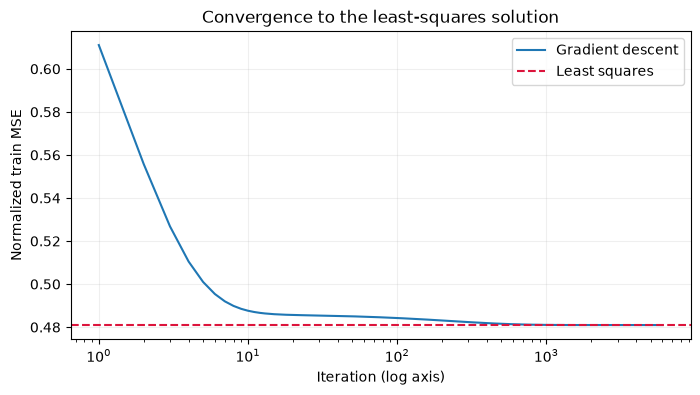

In [6]:
plt.plot(np.arange(1, len(loss_history)+1), loss_history, label="Gradient descent")
plt.axhline(np.mean((A @ theta_ls - z) ** 2), color="crimson", ls="--", label="Least squares")
plt.xscale("log"); plt.xlabel("Iteration (log axis)"); plt.ylabel("Normalized train MSE")
plt.title("Convergence to the least-squares solution"); plt.legend(); plt.show()


## 4. Проверка градиента через конечные разности

Сравним формулу с изменением loss при небольшом сдвиге одного коэффициента.
Такая проверка обнаруживает потерянный множитель 2, знак или неверный axis.
Проверять градиент на точке оптимума неудобно: там обе величины почти нулевые.


In [7]:
probe = np.linspace(-0.2, 0.2, A.shape[1])
analytic = 2 * A.T @ (A @ probe - z) / len(A)
numeric = np.zeros_like(probe)
eps = 1e-6
for j in range(len(probe)):
    shift = np.zeros_like(probe); shift[j] = eps
    numeric[j] = (np.mean((A @ (probe + shift) - z) ** 2)
                  - np.mean((A @ (probe - shift) - z) ** 2)) / (2 * eps)
assert np.allclose(analytic, numeric, atol=1e-7)
print("Максимальная ошибка градиента:", np.max(np.abs(analytic - numeric)))


Максимальная ошибка градиента: 9.434814041142658e-11


## 5. Библиотечный baseline и CV внутри train

`DummyRegressor` предсказывает среднее train. `Pipeline` заново обучает scaler
в каждом fold. У `neg_root_mean_squared_error` знак отрицательный, потому что
scoring API максимизирует оценку. Возвращаем знак, чтобы читать ошибку в единицах цели.


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
models = {"mean baseline": DummyRegressor(),
          "OLS": make_pipeline(StandardScaler(), LinearRegression())}
rows = []
for name, model in models.items():
    scores = -cross_val_score(model, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
    rows.append({"model": name, "CV RMSE mean": scores.mean(), "CV fold SD": scores.std()})
display(pd.DataFrame(rows).round(2))


,model,CV RMSE mean,CV fold SD
0,mean baseline,78.14,3.12
1,OLS,56.12,3.13


## 6. Ridge: обмен небольшого смещения на устойчивость

scikit-learn минимизирует $\|y-Xw\|_2^2+\alpha\|w\|_2^2$.
Свободный член не штрафуется. Масштабировать признаки нужно до Ridge,
иначе одинаковый штраф имеет разный смысл в разных единицах.
Сетку `alpha` выбираем заранее; test в подборе не участвует.


In [9]:
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1)
ridge_search.fit(X_train, y_train)
cv_table = pd.DataFrame(ridge_search.cv_results_)
display(cv_table[["param_ridge__alpha", "mean_test_score", "std_test_score"]]
        .rename(columns={"mean_test_score": "negative_CV_RMSE"}))
print("Зафиксировали alpha:", ridge_search.best_params_)


,param_ridge__alpha,negative_CV_RMSE,std_test_score
0,0.01,-56.117403,3.133418
1,0.10,-56.107984,3.140388
2,1.00,-56.071072,3.198456
3,10.00,-56.108397,3.304098
4,100.00,-56.832329,3.085597
5,1000.00,-65.364294,3.064320


Зафиксировали alpha: {'ridge__alpha': 1.0}


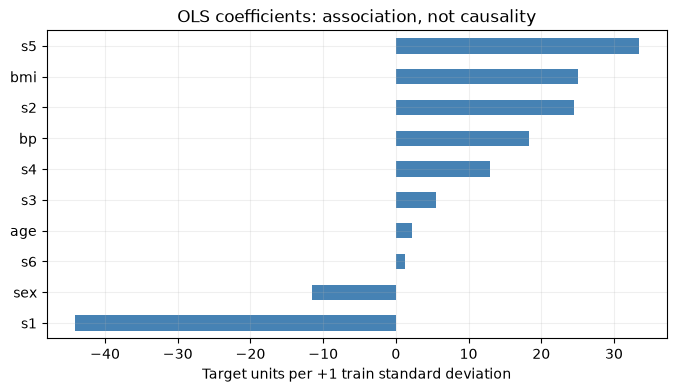

In [10]:
# Численная проверка своей least-squares реализации относительно sklearn на train.
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
scratch_train = (A @ theta_ls) * target_std + target_mean
assert np.allclose(scratch_train, ols.predict(X_train), atol=1e-7)
coefficients = pd.Series(ols[-1].coef_, index=X_train.columns).sort_values()
coefficients.plot.barh(color="steelblue")
plt.xlabel("Target units per +1 train standard deviation")
plt.title("OLS coefficients: association, not causality"); plt.show()


## 7. Открываем test один раз

Список моделей, метрики и alpha уже зафиксированы. Теперь проверим baseline,
OLS и выбранный Ridge на одном holdout. Это финальный отчёт, а не очередной
раунд выбора. `R²` может быть отрицательным: модель может проиграть константе.


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
final_models = {"mean baseline": DummyRegressor().fit(X_train, y_train),
                "OLS": ols, "Ridge (CV choice)": ridge_search.best_estimator_}
final_rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    final_rows.append({"model": name, "MAE": mean_absolute_error(y_test, pred),
                       "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                       "R2": r2_score(y_test, pred)})
display(pd.DataFrame(final_rows).round(3))
test_pred = ridge_search.predict(X_test)
assert test_pred.shape == y_test.shape and np.isfinite(test_pred).all()


,model,MAE,RMSE,R2
0,mean baseline,65.527,74.881,-0.014
1,OLS,41.549,53.370,0.485
2,Ridge (CV choice),41.507,53.318,0.486


## 8. Диагностика ошибок

На графике остатков ищем кривизну, рост разброса и отдельные крупные ошибки.
Test-диагностика помогает сформировать **гипотезу для следующего эксперимента**;
если изменить модель после этого графика, текущий test уже не независимый финальный экзамен.


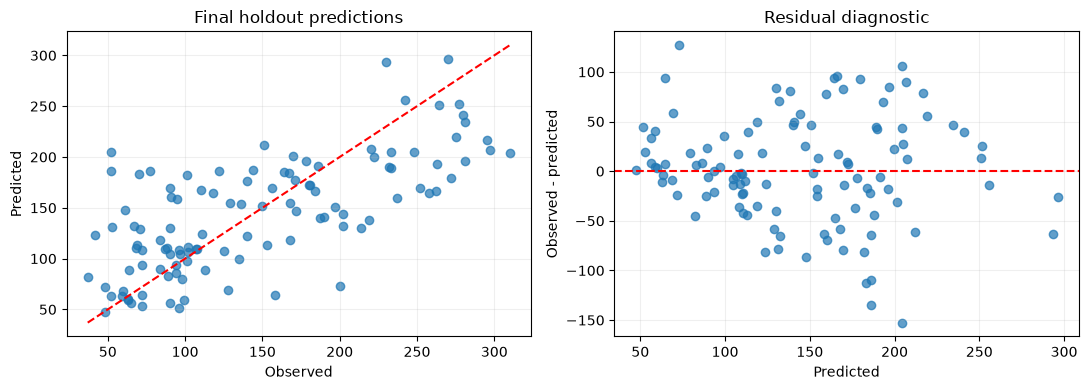

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_pred, alpha=0.7)
low, high = min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(xlabel="Observed", ylabel="Predicted", title="Final holdout predictions")
residuals = y_test.to_numpy() - test_pred
axes[1].scatter(test_pred, residuals, alpha=0.7); axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Predicted", ylabel="Observed - predicted", title="Residual diagnostic")
plt.tight_layout(); plt.show()


## Обсуждение и перенос

1. Почему равенство предсказаний двух решателей полезнее простого утверждения «код работает»?
2. Объясните разницу между train MSE, средним CV RMSE и итоговым test RMSE.
3. Какие признаки могут быть связаны друг с другом, и как это влияет на коэффициенты?
4. Чем предсказание отличается от оценки причинного эффекта изменения BMI?

**Проверка готовности:** есть baseline, корректный split, численно проверенный градиент,
CV внутри train, единственный финальный holdout и ограничения интерпретации.

Первоисточники: [Stanford CS229 notes](https://cs229.stanford.edu/main_notes.pdf),
[scikit-learn linear models](https://scikit-learn.org/stable/modules/linear_model.html),
[Ridge API](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html),
[предотвращение утечки](https://scikit-learn.org/stable/common_pitfalls.html).
Код и русский учебный разбор написаны для курса; это не скопированный университетский notebook.
